In [1]:
!pip install rasterio scikit-learn matplotlib numpy -q
import rasterio, numpy as np, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

In [2]:
!pip install rasterio scikit-learn matplotlib numpy -q
import rasterio, numpy as np, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
print("ALL SET")

ALL SET


In [3]:
!ls -lh /content/Browser_images.zip
!file /content/Browser_images.zip

ls: cannot access '/content/Browser_images.zip': No such file or directory
/content/Browser_images.zip: cannot open `/content/Browser_images.zip' (No such file or directory)


In [10]:
!unzip -o /content/Browser_images.zip -d /content/data
!ls -lh /content/data

Archive:  /content/Browser_images.zip
  inflating: /content/data/2026-09-29-00_00_2026-09-29-23_59_Sentinel-2_L2A_B03_(Raw).tiff  
  inflating: /content/data/2026-09-29-00_00_2026-09-29-23_59_Sentinel-2_L2A_B04_(Raw).tiff  
  inflating: /content/data/2026-09-29-00_00_2026-09-29-23_59_Sentinel-2_L2A_B08_(Raw).tiff  
  inflating: /content/data/2026-09-29-00_00_2026-09-29-23_59_Sentinel-2_L2A_True_color.tiff  
  inflating: /content/data/2026-09-29-00_00_2026-09-29-23_59_Sentinel-2_L2A_NDVI.tiff  
total 8.0M
-rw-r--r-- 1 root root 986K Oct 29 12:53 '2026-09-29-00_00_2026-09-29-23_59_Sentinel-2_L2A_B03_(Raw).tiff'
-rw-r--r-- 1 root root 1.1M Oct 29 12:53 '2026-09-29-00_00_2026-09-29-23_59_Sentinel-2_L2A_B04_(Raw).tiff'
-rw-r--r-- 1 root root 985K Oct 29 12:53 '2026-09-29-00_00_2026-09-29-23_59_Sentinel-2_L2A_B08_(Raw).tiff'
-rw-r--r-- 1 root root 838K Oct 29 12:53  2026-09-29-00_00_2026-09-29-23_59_Sentinel-2_L2A_NDVI.tiff
-rw-r--r-- 1 root root 4.2M Oct 29 12:53  2026-09-29-00_00_2026-09-2

Image size: (545, 773)


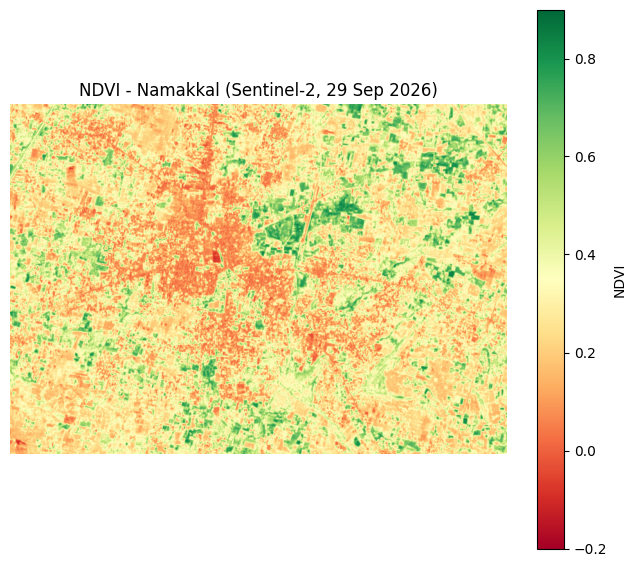

Water/cloud (<0): 0.2 %
Bare/built-up (0-0.2): 25.9 %
Sparse veg (0.2-0.5): 60.1 %
Dense veg (>0.5): 13.9 %


In [12]:
import os, rasterio, numpy as np, matplotlib.pyplot as plt

d = "/content/data/"
files = os.listdir(d)

p3 = d + [f for f in files if "B03" in f][0]
p4 = d + [f for f in files if "B04" in f][0]
p8 = d + [f for f in files if "B08" in f][0]

with rasterio.open(p4) as s: red = s.read(1).astype("float32")
with rasterio.open(p8) as s: nir = s.read(1).astype("float32")

print("Image size:", red.shape)

ndvi = (nir - red) / (nir + red + 1e-10)

plt.figure(figsize=(8, 7))
im = plt.imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.9)
plt.colorbar(im, label="NDVI")
plt.title("NDVI - Namakkal (Sentinel-2, 29 Sep 2026)")
plt.axis("off")
plt.savefig("ndvi_map.png", dpi=200, bbox_inches="tight")
plt.show()

total = ndvi.size
print("Water/cloud (<0):", round((ndvi < 0).sum() / total * 100, 1), "%")
print("Bare/built-up (0-0.2):", round(((ndvi >= 0) & (ndvi < 0.2)).sum() / total * 100, 1), "%")
print("Sparse veg (0.2-0.5):", round(((ndvi >= 0.2) & (ndvi < 0.5)).sum() / total * 100, 1), "%")
print("Dense veg (>0.5):", round((ndvi >= 0.5).sum() / total * 100, 1), "%")

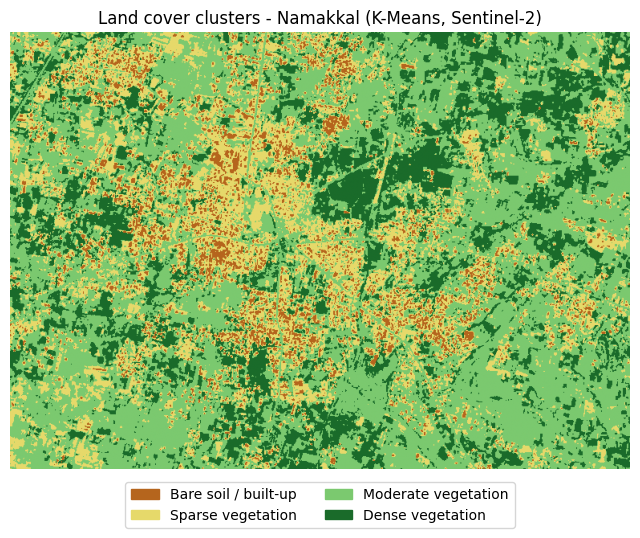

Silhouette score: 0.382
Bare soil / built-up : 5.8 %
Sparse vegetation : 22.5 %
Moderate vegetation : 50.0 %
Dense vegetation : 21.7 %


In [13]:
import os, rasterio, numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

d = "/content/data/"
files = os.listdir(d)

def band(name):
    path = d + [f for f in files if name in f][0]
    with rasterio.open(path) as s:
        return s.read(1).astype("float32")

green, red, nir = band("B03"), band("B04"), band("B08")
ndvi = (nir - red) / (nir + red + 1e-10)

H, W = red.shape
X = np.nan_to_num(np.stack([green, red, nir, ndvi], axis=-1).reshape(-1, 4))
Xs = StandardScaler().fit_transform(X)

K = 4
labels = KMeans(n_clusters=K, random_state=42, n_init=10).fit(Xs).labels_

# rank clusters from lowest to highest mean NDVI
means = [ndvi.ravel()[labels == k].mean() for k in range(K)]
rank = np.zeros(K, dtype=int)
for r, k in enumerate(np.argsort(means)):
    rank[k] = r
classes = rank[labels].reshape(H, W)

names = ["Bare soil / built-up", "Sparse vegetation", "Moderate vegetation", "Dense vegetation"]
colors = ["#b5651d", "#e6d96a", "#7bc96f", "#1a6b2a"]

plt.figure(figsize=(8, 7))
plt.imshow(classes, cmap=ListedColormap(colors), vmin=0, vmax=K - 1)
plt.legend(handles=[Patch(color=colors[i], label=names[i]) for i in range(K)],
           loc="lower center", bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.title("Land cover clusters - Namakkal (K-Means, Sentinel-2)")
plt.axis("off")
plt.savefig("landcover_map.png", dpi=200, bbox_inches="tight")
plt.show()

idx = np.random.RandomState(42).choice(len(Xs), 10000, replace=False)
print("Silhouette score:", round(silhouette_score(Xs[idx], labels[idx]), 3))
for r in range(K):
    print(names[r], ":", round((classes == r).sum() / (classes.size / 100), 1), "%")

Pixel area (ha): 0.00976 | Total area (ha): 4113.1


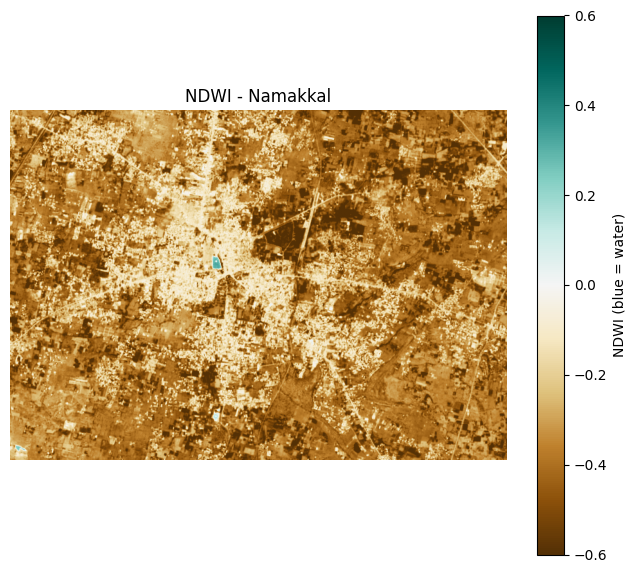

Water area (NDWI > 0): 5.0 ha

NDVI classes (hectares):
  Water/cloud (<0) : 8.2 ha
  Bare/built-up (0-0.2) : 1063.9 ha
  Sparse veg (0.2-0.5) : 2469.9 ha
  Dense veg (>0.5) : 571.0 ha

K-Means classes (hectares):
  Bare soil / built-up : 240.6 ha
  Sparse vegetation : 925.5 ha
  Moderate vegetation : 2056.3 ha
  Dense vegetation : 890.6 ha

Copernicus NDVI file -> bands: 3 | dtype: float32
This file is a colour-rendered image, not raw NDVI values, so skipping validation.

Saved: ndwi_map.png, ndvi_namakkal.tif
Pixel area (ha): 0.00976 | Total area (ha): 4113.1


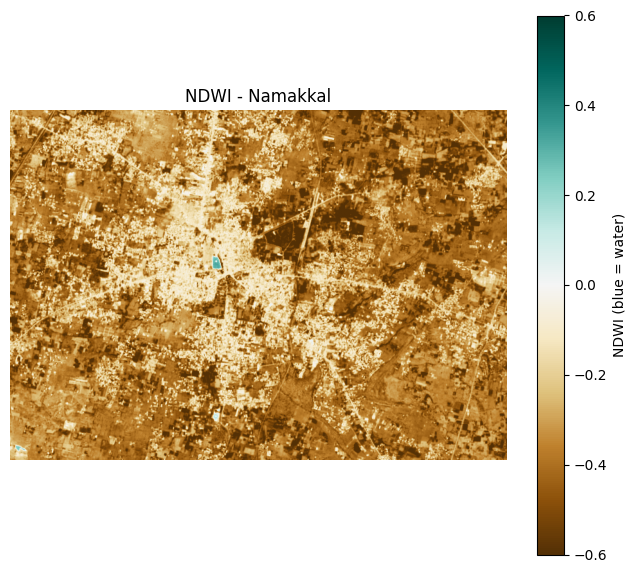

Water area (NDWI > 0): 5.0 ha

NDVI classes (hectares):
  Water/cloud (<0) : 8.2 ha
  Bare/built-up (0-0.2) : 1063.9 ha
  Sparse veg (0.2-0.5) : 2469.9 ha
  Dense veg (>0.5) : 571.0 ha

K-Means classes (hectares):
  Bare soil / built-up : 240.6 ha
  Sparse vegetation : 925.5 ha
  Moderate vegetation : 2056.3 ha
  Dense vegetation : 890.6 ha

Copernicus NDVI file -> bands: 3 | dtype: float32
This file is a colour-rendered image, not raw NDVI values, so skipping validation.

Saved: ndwi_map.png, ndvi_namakkal.tif


In [15]:
import os, rasterio, numpy as np, matplotlib.pyplot as plt

d = "/content/data/"
files = os.listdir(d)
def path(name): return d + [f for f in files if name in f][0]
def band(name):
    with rasterio.open(path(name)) as s:
        return s.read(1).astype("float32")

green, red, nir = band("B03"), band("B04"), band("B08")
ndvi = (nir - red) / (nir + red + 1e-10)

# ---------- pixel area in hectares ----------
with rasterio.open(path("B04")) as s:
    tr, bounds, crs, profile = s.transform, s.bounds, s.crs, s.profile
if crs.is_geographic:
    lat = (bounds.top + bounds.bottom) / 2
    w_m = abs(tr.a) * 111320 * np.cos(np.radians(lat))
    h_m = abs(tr.e) * 110574
    pixel_ha = w_m * h_m / 10000
else:
    pixel_ha = abs(tr.a * tr.e) / 10000
print("Pixel area (ha):", round(pixel_ha, 5), "| Total area (ha):", round(pixel_ha * ndvi.size, 1))

# ---------- 1. NDWI water map ----------
ndwi = (green - nir) / (green + nir + 1e-10)
plt.figure(figsize=(8, 7))
im = plt.imshow(ndwi, cmap="BrBG", vmin=-0.6, vmax=0.6)
plt.colorbar(im, label="NDWI (blue = water)")
plt.title("NDWI - Namakkal")
plt.axis("off")
plt.savefig("ndwi_map.png", dpi=200, bbox_inches="tight")
plt.show()
print("Water area (NDWI > 0):", round((ndwi > 0).sum() * pixel_ha, 1), "ha")

# ---------- 2. Hectares per class ----------
print("\nNDVI classes (hectares):")
bins = [("Water/cloud (<0)", ndvi < 0),
        ("Bare/built-up (0-0.2)", (ndvi >= 0) & (ndvi < 0.2)),
        ("Sparse veg (0.2-0.5)", (ndvi >= 0.2) & (ndvi < 0.5)),
        ("Dense veg (>0.5)", ndvi >= 0.5)]
for n, m in bins:
    print(" ", n, ":", round(m.sum() * pixel_ha, 1), "ha")

if "classes" in globals():
    print("\nK-Means classes (hectares):")
    for r in range(4):
        print(" ", names[r], ":", round((classes == r).sum() * pixel_ha, 1), "ha")

# ---------- 3. Validate against Copernicus NDVI ----------
with rasterio.open(path("NDVI")) as s:
    print("\nCopernicus NDVI file -> bands:", s.count, "| dtype:", s.dtypes[0])
    if s.count == 1 and s.read(1).shape == ndvi.shape:
        cop = s.read(1).astype("float32")
        ok = np.isfinite(cop) & np.isfinite(ndvi)
        a, b = ndvi[ok], cop[ok]
        print("Correlation:", round(np.corrcoef(a, b)[0, 1], 4))
        print("RMSE:", round(float(np.sqrt(((a - b) ** 2).mean())), 4))
        print("MAE:", round(float(np.abs(a - b).mean()), 4))
        i = np.random.RandomState(0).choice(len(a), 5000, replace=False)
        plt.figure(figsize=(5, 5))
        plt.scatter(b[i], a[i], s=2, alpha=0.4)
        plt.plot([-0.2, 0.9], [-0.2, 0.9], "r--")
        plt.xlabel("Copernicus NDVI"); plt.ylabel("My NDVI")
        plt.title("NDVI validation")
        plt.savefig("ndvi_validation.png", dpi=200, bbox_inches="tight")
        plt.show()
    else:
        print("This file is a colour-rendered image, not raw NDVI values, so skipping validation.")

# ---------- 4. Save NDVI as GeoTIFF (opens in QGIS) ----------
profile.update(dtype="float32", count=1, compress="lzw")
with rasterio.open("ndvi_namakkal.tif", "w", **profile) as dst:
    dst.write(ndvi.astype("float32"), 1)
print("\nSaved: ndwi_map.png, ndvi_namakkal.tif")

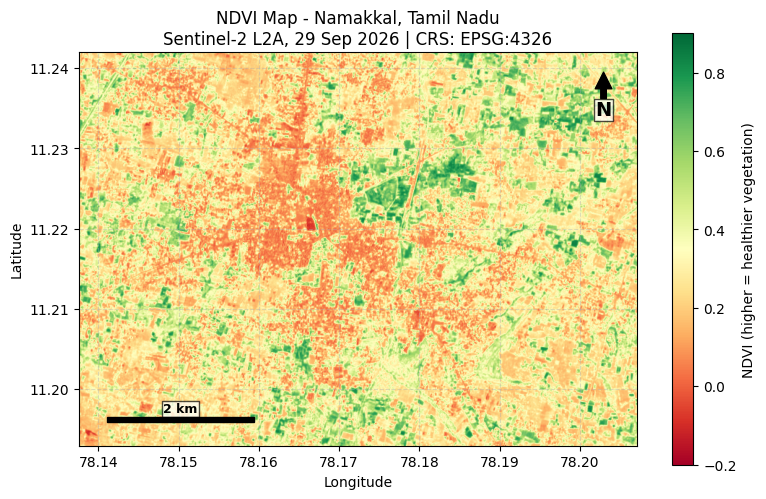

In [16]:
import rasterio, numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

with rasterio.open("ndvi_namakkal.tif") as s:
    ndvi = s.read(1); b = s.bounds; crs = s.crs

W, H = b.right - b.left, b.top - b.bottom
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.9,
               extent=[b.left, b.right, b.bottom, b.top])

# scale bar (2 km)
km = 2
lat = (b.top + b.bottom) / 2
length = km / (111.32 * np.cos(np.radians(lat))) if crs.is_geographic else km * 1000
x0, y0 = b.left + W * 0.05, b.bottom + H * 0.06
ax.add_patch(Rectangle((x0, y0), length, H * 0.012, color="black", zorder=5))
ax.text(x0 + length / 2, y0 + H * 0.025, f"{km} km", ha="center", fontsize=9,
        weight="bold", bbox=dict(facecolor="white", alpha=0.7, pad=1))

# north arrow
ax.annotate("N", xy=(0.94, 0.95), xytext=(0.94, 0.84), xycoords="axes fraction",
            textcoords="axes fraction", ha="center", fontsize=14, weight="bold",
            arrowprops=dict(facecolor="black", width=4, headwidth=12),
            bbox=dict(facecolor="white", alpha=0.7, pad=1))

cb = plt.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("NDVI (higher = healthier vegetation)")
ax.set_xlabel("Longitude" if crs.is_geographic else "Easting")
ax.set_ylabel("Latitude" if crs.is_geographic else "Northing")
ax.set_title(f"NDVI Map - Namakkal, Tamil Nadu\nSentinel-2 L2A, 29 Sep 2026 | CRS: {crs}")
ax.grid(True, ls="--", alpha=0.4)
plt.savefig("ndvi_map_final.png", dpi=250, bbox_inches="tight")
plt.show()